# 第 1 節｜20 分鐘實作：預測小考分數

使用 `LinearRegression` 訓練、預測，再看四個評估指標。

In [1]:
# Load NumPy for numerical calculations.
# 載入 NumPy，進行數值計算。
import numpy as np

# Load Pandas for tabular data.
# 載入 Pandas，讀取與整理表格。
import pandas as pd

# Load Matplotlib for charts.
# 載入 Matplotlib，繪製圖表。
import matplotlib.pyplot as plt

# Load Path for locating the dataset.
# 載入 Path，協助找到資料集。
from pathlib import Path

# Load the train/test split tool.
# 載入訓練集與測試集切分工具。
from sklearn.model_selection import train_test_split

# Load StandardScaler for z-score scaling.
# 載入 StandardScaler，進行 z-score 標準化。
from sklearn.preprocessing import StandardScaler

# Load basic linear regression.
# 載入最基本的線性迴歸模型。
from sklearn.linear_model import LinearRegression

# Load regression evaluation metrics.
# 載入迴歸評估指標。
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


## 1. 讀取資料

在 Colab 從 `/content/` 讀取；其他環境從目前工作目錄讀取。

| 欄位名稱 | 中文名稱 | 資料型態 | 說明與取值 | 教學用途 |
|---|---|---|---|---|
| `student_id` | 學生編號 | 文字 | `S001`～`S500`，每位學生的唯一編號 | 僅作識別，**不加入 X** |
| `study_hours` | 每日讀書時數 | 數值 | 單位：小時；包含缺漏值與一筆刻意設計的 60 小時異常紀錄 | 數值型特徵 X |
| `practice_questions` | 每日練習題數 | 數值 | 單位：題；例如 `2.0`、`17.0`，包含缺漏值 | 數值型特徵 X |
| `learning_method` | 學習方式 | 名目型類別 | `自習`、`讀書會`、`線上課` | 類別型特徵 X，使用 One-Hot Encoding |
| `attendance_rate` | 出席率 | 數值 | 0～100 的百分比數值；本資料實際範圍為 62～100 | 保留作延伸數值特徵 |
| `sleep_hours` | 每日睡眠時數 | 數值 | 單位：小時；本資料實際範圍為 4.6～9.4 | 保留作延伸數值特徵 |
| `effort_level` | 學習投入程度 | 序位型類別 | `很少` → `偏少` → `普通` → `偏多` → `很多` | 用於理解順序、Spearman／Kendall 等延伸概念 |
| `quiz_score` | 小考分數 | 數值 | 0～100 分；本資料實際範圍為 25～100 | **第 1 節的迴歸目標 y** |
| `passed` | 是否及格 | 二元類別 | `1`＝及格（`quiz_score` ≥ 60）；`0`＝未及格 | **第 2 節的分類目標 y** |

In [2]:
# Look for the CSV in Google Colab.
# 優先在 Colab 的 /content 找到資料集。
file_path = Path("/content/01_機器學習_學生練習資料_500筆.csv")

# Use a local path if Colab's file is unavailable.
# 若沒有 Colab 路徑，就改讀目前工作目錄。
if not file_path.exists():

    # Keep the CSV next to the notebook in a local environment.
    # 本機使用時，將 CSV 放在 Notebook 的工作目錄。
    file_path = Path("01_機器學習_學生練習資料_500筆.csv")

# Load the same 500 student records for the lesson.
# 載入本節使用的 500 筆學生資料。
df = pd.read_csv(file_path)

# Preview the two inputs, learning method, and target.
# 查看兩個數值特徵、學習方式與目標分數。
df[["study_hours", "practice_questions", "learning_method", "quiz_score"]].head()

,study_hours,practice_questions,learning_method,quiz_score
0,1.8,2.0,讀書會,42
1,3.0,17.0,自習,65
2,4.0,18.0,自習,72
3,4.7,16.0,讀書會,70
4,2.2,8.0,讀書會,64


## 2. 缺漏值與異常值

資料中的 60 小時是刻意設計的輸入錯誤；真實資料應先查證。

In [3]:
# Mark the known data-entry error as missing.
# 將已確認輸入錯誤的時數標記為缺漏。
df.loc[df["study_hours"] > 12, "study_hours"] = np.nan

# Check how many records need numerical imputation.
# 看看有多少數值資料需要補值。
df[["study_hours", "practice_questions"]].isna().sum()

study_hours           13
practice_questions     9
dtype: int64

## 3. 把數值與類別特徵合併成 X

`study_hours`、`practice_questions` 是數值；`learning_method` 是類別。切分資料後，用 One-Hot 轉成 0／1；三種特徵一起訓練。

In [4]:
# Select numerical and categorical features together.
# 把數值與類別特徵放進同一份輸入資料。
X = df[["study_hours", "practice_questions", "learning_method"]]

# Use quiz scores as the prediction target.
# 使用小考分數作為預測目標。
y = df["quiz_score"]

# Keep 20 percent of the data for the final test.
# 保留 20% 的資料作為最後測試集。
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Convert categories to 0/1 while keeping numerical columns.
# 將類別轉成 0／1，同時保留原本的數值欄位。
X_train = pd.get_dummies(X_train, dtype=int)

# Encode the test data in the same way.
# 用相同方式轉換測試資料的類別。
X_test = pd.get_dummies(X_test, dtype=int)

# Match the test columns to the training columns.
# 測試資料沿用訓練集的特徵欄位與順序。
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# Preview the combined model inputs.
# 查看數值與 One-Hot 特徵合併後的結果。
X_train.head()

,study_hours,practice_questions,learning_method_線上課,learning_method_自習,learning_method_讀書會
249,3.3,20.0,0,1,0
433,3.3,17.0,0,0,1
19,0.9,6.0,0,1,0
322,3.6,18.0,0,1,0
332,3.2,15.0,0,1,0


## 4. 補值與標準化

只用訓練集計算補值與標準化參數；**只標準化兩個數值欄位**，One-Hot 保持 0／1。

In [5]:
# Identify the columns that need numerical scaling.
# 指定需要補值與標準化的兩個數值欄位。
numeric_cols = ["study_hours", "practice_questions"]

# Calculate missing-value replacements using training data only.
# 只用訓練資料計算數值欄位的中位數。
medians = X_train[numeric_cols].median()

# Replace missing values in training data.
# 補上訓練資料的缺漏值。
X_train = X_train.fillna(medians)

# Apply the same replacements to test data.
# 測試資料沿用訓練資料的中位數。
X_test = X_test.fillna(medians)

# Create the numerical standardizer.
# 建立數值特徵的標準化工具。
scaler = StandardScaler()

# Learn the scale from training numbers only.
# 只用訓練集標準化數值欄，保留 One-Hot 的 0／1。
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])

# Reuse the same scale on test numbers.
# 測試集使用相同標準化規則。
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

## 5. LinearRegression：訓練與預測

In [6]:
# Create a basic linear regression model.
# 建立最基本的線性迴歸模型。
model = LinearRegression()

# Learn the relationship using training examples.
# 讓模型從訓練資料學習特徵與分數的關係。
model.fit(X_train, y_train)

# Predict scores for students the model has not seen.
# 預測模型沒有看過的測試資料。
pred = model.predict(X_test)

## 6. 觀察預測結果與 Metrics

點越靠近虛線，代表預測越接近真實成績。

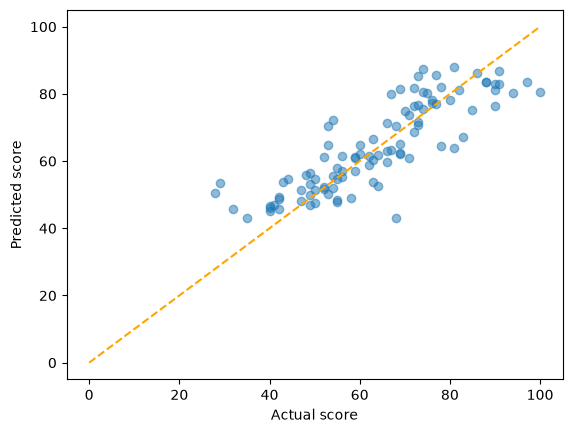

In [7]:
# Plot actual scores against predicted scores.
# 用散佈圖比較真實分數與預測分數。
plt.scatter(y_test, pred, alpha=0.5)

# Show the ideal line for perfectly matched predictions.
# 虛線代表真實與預測分數完全相同。
plt.plot([0, 100], [0, 100], linestyle="--", color="orange")

# Label the actual-score axis.
# 標示真實分數的橫軸。
plt.xlabel("Actual score")

# Label the predicted-score axis.
# 標示預測分數的縱軸。
plt.ylabel("Predicted score")

# Display the comparison chart.
# 顯示模型預測結果。
plt.show()

In [8]:
# Calculate MSE once so it can also be used for RMSE.
# 先算 MSE，讓 RMSE 可以直接沿用結果。
mse = mean_squared_error(y_test, pred)

# Show the average size of the absolute errors.
# 顯示平均絕對誤差 MAE。
print(f"MAE: {mean_absolute_error(y_test, pred):.2f}")

# Show the average squared error.
# 顯示均方誤差 MSE。
print(f"MSE: {mse:.2f}")

# Show the error after returning to the score unit.
# 顯示開根號後的均方根誤差 RMSE。
print(f"RMSE: {np.sqrt(mse):.2f}")

# Show how well predictions explain score differences.
# 顯示模型的決定係數 R²。
print(f"R²: {r2_score(y_test, pred):.2f}")

MAE: 6.61
MSE: 74.12
RMSE: 8.61
R²: 0.71


## 7. 三位新同學：用訓練好的模型預測

不需要重新訓練。新資料要使用相同的 One-Hot 欄位、補值與標準化規則，再交給 `model.predict()`。

In [9]:
# Enter three new students with numeric and categorical inputs.
# 輸入三位新同學的數值與類別特徵。
new_data = pd.DataFrame([
    [1.0, 3, "自習"],
    [3.5, 14, "讀書會"],
    [6.0, 25, "線上課"]
], columns=["study_hours", "practice_questions", "learning_method"])

# Create One-Hot columns in the same order as training.
# 將類別轉成 One-Hot，並對齊訓練時的欄位順序。
X_new = pd.get_dummies(new_data, dtype=int).reindex(columns=X_train.columns, fill_value=0)

# Reuse training medians if any numeric values are missing.
# 數值若有缺漏，沿用訓練資料計算的中位數。
X_new = X_new.fillna(medians)

# Apply the same numerical scaling used for training.
# 使用訓練時建立的標準化規則。
X_new[numeric_cols] = scaler.transform(X_new[numeric_cols])

# Predict the three quiz scores with the existing model.
# 使用已訓練模型，預測三位同學的小考分數。
new_data["預測小考分數"] = model.predict(X_new).round(1)

# Display new inputs and their predictions in one table.
# 在同一張表查看三筆輸入與預測結果。
new_data

,study_hours,practice_questions,learning_method,預測小考分數
0,1.0,3,自習,45.7
1,3.5,14,讀書會,66.4
2,6.0,25,線上課,82.4


## 選做｜Pearson 很高，就該刪特徵嗎？（約 3 分鐘）

先觀察讀書時數與練習題數的關係，再比較**保留所有特徵**和**只移除讀書時數**的驗證 MAE。兩組模型都保留 One-Hot 類別特徵；不使用最後的測試集挑特徵。

In [10]:
# Set aside validation examples from the training portion.
# 從訓練資料再切出驗證集。
X_fit, X_val, y_fit, y_val = train_test_split(X.loc[y_train.index], y_train, test_size=0.25, random_state=7)

# Check whether two numerical inputs are strongly correlated.
# 查看兩個數值特徵的 Pearson 相關係數。
r = X_fit["study_hours"].corr(X_fit["practice_questions"])

# Show the correlation coefficient.
# 顯示相關係數。
print(f"Pearson r: {r:.2f}")

# Encode categories without removing numerical features.
# 將類別轉成 One-Hot，同時保留兩個數值欄位。
X_fit = pd.get_dummies(X_fit, dtype=int)

# Use the fitting-data columns for validation.
# 驗證集的 One-Hot 欄位必須與建模資料相同。
X_val = pd.get_dummies(X_val, dtype=int).reindex(columns=X_fit.columns, fill_value=0)

# Compute numerical replacements from fitting data only.
# 只用建模資料的數值欄計算補值。
median_fit = X_fit[numeric_cols].median()

# Fill missing fitting records.
# 補齊建模資料的缺漏值。
X_fit = X_fit.fillna(median_fit)

# Use the same replacement values on validation records.
# 驗證資料使用相同的中位數補值。
X_val = X_val.fillna(median_fit)

Pearson r: 0.85


In [11]:
# Fit a model using numbers and One-Hot features together.
# 使用全部數值與類別特徵訓練模型。
full_model = LinearRegression().fit(X_fit, y_fit)

# Train another model without study hours.
# 只移除讀書時數，其餘特徵都保留。
simple_model = LinearRegression().fit(X_fit.drop(columns="study_hours"), y_fit)

# Measure validation MAE with all inputs.
# 計算保留全部特徵的驗證誤差。
full_mae = mean_absolute_error(y_val, full_model.predict(X_val))

# Measure validation MAE after removing one input.
# 計算移除讀書時數後的驗證誤差。
simple_mae = mean_absolute_error(y_val, simple_model.predict(X_val.drop(columns="study_hours")))

# Show both validation errors for comparison.
# 比較移除特徵前後的 MAE。
print(f"保留全部特徵 MAE: {full_mae:.2f}")

# Show the error after removing study hours.
# 顯示移除讀書時數後的 MAE。
print(f"移除讀書時數 MAE: {simple_mae:.2f}")

保留全部特徵 MAE: 6.91
移除讀書時數 MAE: 7.26


**觀察重點：** Pearson 高，可能代表兩個特徵提供類似資訊，但**不等於其中一欄沒有用**。如果刪除後驗證 MAE 變大，就先保留它。正式測試集只用來做最後評估。